# A ball rolling down an error surface (gradient descent)
The terrain below is an error surface. Every pair of parameters (a, b) has one height, and that height is the error. The goal is to start from a random point and use gradient descent to reach the bottom of a valley, where the error is smallest.

The steps follow the same structure as the linear regression notebook: initializer, training loop, forward, loss, backward, update.

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cbook
from matplotlib.colors import LightSource
from scipy.interpolate import RegularGridInterpolator

## Data: the terrain
We load the same terrain as in the 3D plot. `z` is the elevation, which we treat as the error.

In [32]:
dem = cbook.get_sample_data('jacksboro_fault_dem.npz')
z = dem['elevation']
nrows, ncols = z.shape
x = np.linspace(dem['xmin'], dem['xmax'], ncols)
y = np.linspace(dem['ymin'], dem['ymax'], nrows)
x, y = np.meshgrid(x, y)

region = np.s_[5:50, 5:50]
x, y, z = x[region], y[region], z[region]

print(z.shape)

(45, 45)


## Rescale
Longitude, latitude and meters have very different sizes. We rescale a and b to the range 0 to 1, and the error to the range 0 to 1, so that one learning rate works well for both directions.

In [33]:
a_axis = np.linspace(0, 1, z.shape[1])
b_axis = np.linspace(0, 1, z.shape[0])
error_surface = (z - z.min()) / (z.max() - z.min())

error_surface.min(), error_surface.max()

(np.float64(0.0), np.float64(1.0))

## Error function and its gradient
`E(a, b)` gives the height at any point, even between grid points (interpolation).

`gradient(a, b)` gives the slope: how much the error changes if we move a little in the a direction and a little in the b direction. A positive slope means uphill, so we will move the opposite way.

In [34]:
E_interp = RegularGridInterpolator((b_axis, a_axis), error_surface)

def E(a, b):
    return float(E_interp([[b, a]])[0])

def gradient(a, b, h=1e-3):
    a_hi, a_lo = min(a + h, 1), max(a - h, 0)
    b_hi, b_lo = min(b + h, 1), max(b - h, 0)
    dE_da = (E(a_hi, b) - E(a_lo, b)) / (a_hi - a_lo)
    dE_db = (E(a, b_hi) - E(a, b_lo)) / (b_hi - b_lo)
    return np.array([dE_da, dE_db])

## Random initializer
The ball starts at a random point. Every time you run this cell, the start is different.

In [35]:
# Initializer (random start, different on every run)
a = np.random.uniform(0, 1)
b = np.random.uniform(0, 1)

theta = np.array([a, b])

print(f"Start point: a={a:.3f}, b={b:.3f}, error={E(a, b):.3f}")

Start point: a=0.814, b=0.500, error=0.338


## Training loop
In every step:
1. Forward: find the height (the error) at the current point.
2. Loss: save that height, so we can plot it later.
3. Backward: compute the slope.
4. Update: move a small step downhill, against the slope.

There are no mini-batches here, because the error comes from the terrain and not from data samples.

In [36]:
learning_rate = 0.01
n_epochs = 1000

cost_function = []
theta_history = [theta.copy()]

for epoch in range(n_epochs):
    # Forward
    loss = E(theta[0], theta[1])
    cost_function.append(loss)

    # Backward
    grad = gradient(theta[0], theta[1])

    # Optimizer (Update Weights)
    theta = theta - learning_rate * grad
    theta = np.clip(theta, 0, 1)   # keep the ball inside the terrain

    theta_history.append(theta.copy())

print(f"Final point: a={theta[0]:.3f}, b={theta[1]:.3f}, error={E(theta[0], theta[1]):.3f}")

Final point: a=0.432, b=0.659, error=0.006


## Loss curve
The error should go down while the ball rolls into a valley.

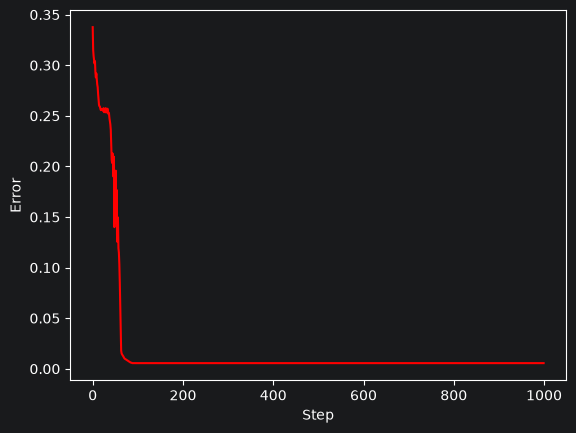

In [37]:
plt.plot(cost_function, "r")
plt.xlabel("Step")
plt.ylabel("Error")
plt.show()

## The path on the terrain
The red line is the path of the ball. The black dot is the random start and the yellow dot is where the ball stopped.

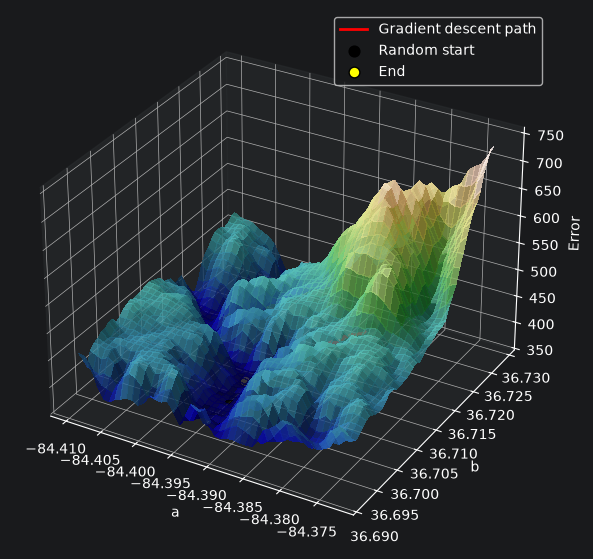

In [38]:
path = np.array(theta_history)
path_err = np.array([E(p[0], p[1]) for p in path])

# Map the path back to the original axes, only for plotting
px = x[0, 0] + path[:, 0] * (x[0, -1] - x[0, 0])
py = y[0, 0] + path[:, 1] * (y[-1, 0] - y[0, 0])
pz = z.min() + path_err * (z.max() - z.min())

fig, ax = plt.subplots(figsize=(9, 7), subplot_kw=dict(projection='3d'))
ls = LightSource(270, 45)
rgb = ls.shade(z, cmap=plt.colormaps["gist_earth"], vert_exag=0.1, blend_mode='soft')
ax.plot_surface(x, y, z, rstride=1, cstride=1, facecolors=rgb,
                linewidth=0, antialiased=False, shade=False, alpha=0.8)
ax.plot(px, py, pz + 5, color='red', linewidth=2, label='Gradient descent path')
ax.scatter(px[0], py[0], pz[0] + 5, color='black', s=60, label='Random start')
ax.scatter(px[-1], py[-1], pz[-1] + 5, color='yellow', edgecolor='black', s=60, label='End')
ax.set_xlabel("a")
ax.set_ylabel("b")
ax.set_zlabel("Error")
ax.legend()
plt.show()

## Top view
The same path seen from above, on the contour lines of the terrain.

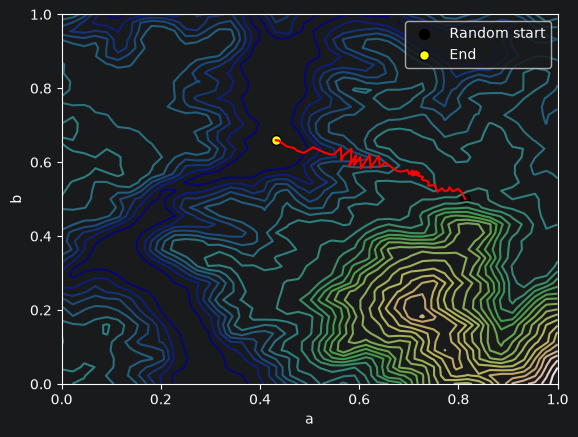

In [39]:
plt.contour(a_axis, b_axis, error_surface, levels=30, cmap="gist_earth")
plt.plot(path[:, 0], path[:, 1], "r", linewidth=1.5)
plt.scatter(path[0, 0], path[0, 1], color="black", s=50, label="Random start")
plt.scatter(path[-1, 0], path[-1, 1], color="yellow", edgecolor="black", s=50, label="End")
plt.xlabel("a")
plt.ylabel("b")
plt.legend()
plt.show()

## Compare with the lowest point of the whole terrain
The ball only finds the valley it started near (a local minimum). The deepest point of the whole terrain may be in another valley. Run the random initializer again and see where the ball ends up.

In [40]:
lowest = error_surface.min()
print(f"Error reached by the ball: {E(theta[0], theta[1]):.3f}")
print(f"Lowest error in the whole terrain: {lowest:.3f}")

Error reached by the ball: 0.006
Lowest error in the whole terrain: 0.000
